# Step 5 — Dipendenza seriale e scelta dei lag

Confrontiamo la memoria delle serie e modelli della media con 1, 2, 5 e 10 lag. I modelli sono diagnostici: un autoregressivo gaussiano non è un kernel valido per simulare X fuori da [0, 2].

Fonte: artefatti verificati dello [step 1](../step1/dataset_ethereum.ipynb), log su wei/gas. L’analisi usa gli ultimi 30.000 blocchi consecutivi: training 20.000, validation 5.000, testing 5.000. Il testing misura; soltanto la validation sceglie il numero di lag. Le conclusioni riguardano questa finestra, non l’intero dataset.

**Risultato osservato:** la validation sceglie 10 lag per tutte le variabili; nel testing il MSE scende del 22,54% per log p50, 12,10% per log p90, 17,85% per dispersione e 1,14% per X rispetto ad AR(1). Rimane dipendenza nei residui. Dettagli e limiti nei [findings](findings.md).

## 0. Input, periodo e ruoli

Verifichiamo identità e continuità del dataset, quindi fissiamo una finestra contigua.
Le prime dieci righe forniscono i lag: tutti i modelli confrontati hanno gli stessi target.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from scipy.stats import chi2
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

project_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs/CONTEXT.md").is_file()
)
source = project_root / "outputs/notebook_diagnostics/ethereum/step1"
summary = json.loads((source / "preprocessing_summary.json").read_text())
assert summary["chain_id"] == 1
assert summary["dataset_id"] == "e7b17cfb-320d-4e6c-93c1-06dbc24f312d"
df = pd.read_parquet(source / "ethereum_blocks_diagnostics.parquet")
assert len(df) == summary["rows"]
assert np.all(np.diff(df["block_number"]) == 1)
output_directory = project_root / "outputs/notebook_diagnostics/ethereum/step5"
output_directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "figure.figsize": (11, 4),
        "figure.dpi": 110,
        "font.size": 11,
        "axes.grid": True,
        "grid.alpha": 0.2,
    }
)
pd.set_option("display.max_rows", 24)
pd.set_option("display.max_columns", 12)
variables = {
    "X": "X",
    "log_p50": "log_effective_priority_fee_per_gas_p50",
    "log_p90": "log_effective_priority_fee_per_gas_p90",
    "dispersion": "priority_fee_dispersion",
}

SAMPLE_SIZE = 30000
MAX_LAG = 10
TRAIN_END = 20000
VALID_END = 25000
CANDIDATE_LAGS = (1, 2, 5, 10)
assert len(df) >= SAMPLE_SIZE
sample = df.tail(SAMPLE_SIZE).reset_index(drop=True)
assert sample[list(variables.values())].notna().all().all()
assert sample["X"].between(0, 2).all()
display(
    pd.DataFrame(
        {
            "role": ["training", "validation", "testing"],
            "first_block": sample.loc[[MAX_LAG, TRAIN_END, VALID_END], "block_number"].to_numpy(),
            "last_block": sample.loc[
                [TRAIN_END - 1, VALID_END - 1, SAMPLE_SIZE - 1], "block_number"
            ].to_numpy(),
            "first_UTC": pd.to_datetime(
                sample.loc[[MAX_LAG, TRAIN_END, VALID_END], "timestamp"].to_numpy(),
                unit="s",
                utc=True,
            ),
            "last_UTC": pd.to_datetime(
                sample.loc[[TRAIN_END - 1, VALID_END - 1, SAMPLE_SIZE - 1], "timestamp"].to_numpy(),
                unit="s",
                utc=True,
            ),
        }
    )
)

,role,first_block,last_block,first_UTC,last_UTC
0,training,25560240,25580229,2026-07-18 14:39:23+00:00,2026-07-21 09:34:11+00:00
1,validation,25580230,25585229,2026-07-21 09:34:23+00:00,2026-07-22 02:17:35+00:00
2,testing,25585230,25590229,2026-07-22 02:17:47+00:00,2026-07-22 19:02:47+00:00


## 1. ACF e PACF dei livelli e delle trasformazioni

Cerchiamo memoria lineare nell’utilizzo e nelle priority fee, prima e dopo il log.
I grafici usano blocchi consecutivi del training; nessun sottocampionamento cambia il significato dei lag.

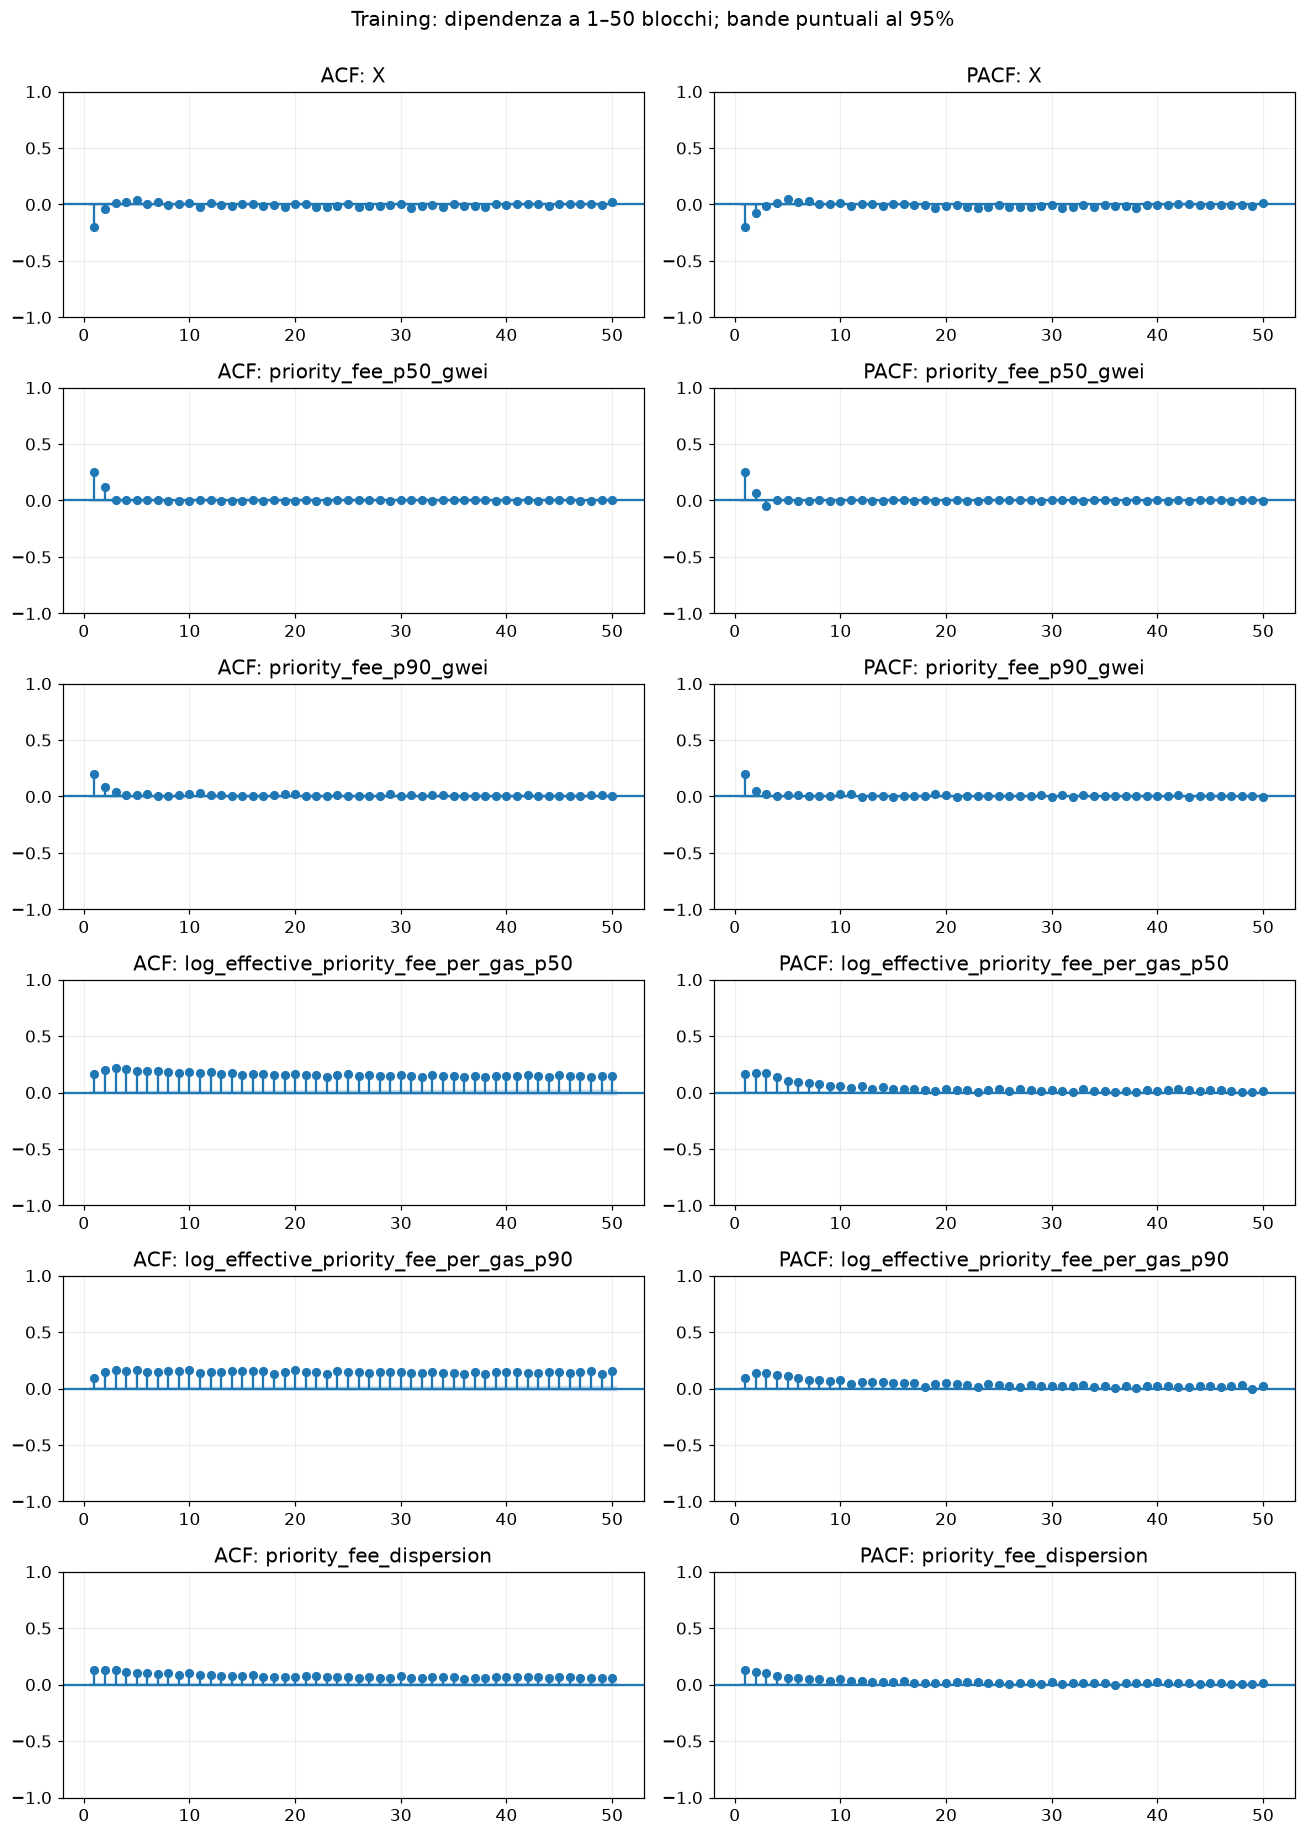

In [2]:
acf_columns = [
    "X",
    "priority_fee_p50_gwei",
    "priority_fee_p90_gwei",
    "log_effective_priority_fee_per_gas_p50",
    "log_effective_priority_fee_per_gas_p90",
    "priority_fee_dispersion",
]
fig, axes = plt.subplots(len(acf_columns), 2, figsize=(12, 17))
for row, column in enumerate(acf_columns):
    values = sample[column].iloc[MAX_LAG:TRAIN_END]
    plot_acf(values, lags=50, fft=True, zero=False, ax=axes[row, 0], title=f"ACF: {column}")
    plot_pacf(values, lags=50, method="ywm", zero=False, ax=axes[row, 1], title=f"PACF: {column}")
fig.suptitle("Training: dipendenza a 1–50 blocchi; bande puntuali al 95%")
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()
plt.close(fig)

## 2. Preparazione dei modelli su target comuni

Stimiamo una sola volta AR(1), AR(2), AR(5) e AR(10) sul training.
Gli stessi target rendono confrontabili i criteri; le sezioni successive riusano queste stime.

In [3]:
def lag_design(values, lag):
    # Il target t vede soltanto valori dei blocchi t-1 ... t-lag.
    target_rows = np.arange(MAX_LAG, len(values))
    return np.column_stack(
        [np.ones(len(target_rows))] + [values[target_rows - j] for j in range(1, lag + 1)]
    )


check_values = np.arange(20.0)
assert np.array_equal(lag_design(check_values, 2)[0], [1, 9, 8])
models = {}
model_rows = []
for name, column in variables.items():
    values = sample[column].to_numpy()
    models[name] = {}
    previous = None
    for lag in CANDIDATE_LAGS:
        design = lag_design(values, lag)
        fit = sm.OLS(values[MAX_LAG:TRAIN_END], design[: TRAIN_END - MAX_LAG]).fit()
        robust = fit.get_robustcov_results(cov_type="HAC", maxlags=50)
        restriction = np.eye(lag + 1)[1 if previous is None else previous[0] + 1 :]
        own_pvalue = float(robust.wald_test(restriction, scalar=True).pvalue)
        lr = np.nan if previous is None else max(0, 2 * (fit.llf - previous[1].llf))
        lr_pvalue = np.nan if previous is None else chi2.sf(lr, lag - previous[0])
        models[name][lag] = fit
        model_rows.append(
            {
                "variable": name,
                "lag": lag,
                "n": int(fit.nobs),
                "AIC": fit.aic,
                "BIC": fit.bic,
                "R2": fit.rsquared,
                "Wald_HAC_added_lags_p": own_pvalue,
                "LR_Gaussian": lr,
                "LR_Gaussian_p": lr_pvalue,
            }
        )
        previous = (lag, fit)
model_comparison = pd.DataFrame(model_rows)
assert model_comparison["n"].nunique() == 1
model_comparison.to_csv(output_directory / "mean_models.csv", index=False)

## 3. L’utilizzo precedente predice quello corrente?

Esaminiamo il coefficiente del primo lag dell’utilizzo con un test Wald HAC.
La significatività è diagnostica; il confronto rolling misurerà il miglioramento predittivo.

In [4]:
display(
    model_comparison.query("variable == 'X' and lag == 1")[
        ["variable", "lag", "R2", "Wald_HAC_added_lags_p"]
    ]
)

,variable,lag,R2,Wald_HAC_added_lags_p
0,X,1,0.038267,1.630949e-68


## 4. Le priority fee precedenti predicono quelle correnti?

Ripetiamo il controllo del primo lag per log p50, log p90 e dispersione.
Sono modelli delle transazioni incluse, non stime del tip che garantisce inclusione.

In [5]:
display(
    model_comparison.query("variable != 'X' and lag == 1")[
        ["variable", "lag", "R2", "Wald_HAC_added_lags_p"]
    ]
)

,variable,lag,R2,Wald_HAC_added_lags_p
4,log_p50,1,0.026801,5.835609e-19
8,log_p90,1,0.009165,4.032703e-15
12,dispersion,1,0.016074,2.581696e-16


## 5. Informazione aggiuntiva dei lag più vecchi

I Wald HAC verificano congiuntamente i nuovi coefficienti rispetto alla specifica precedente.
Confrontiamo 2 contro 1, 5 contro 2 e 10 contro 5 lag, senza usare il testing.

In [6]:
display(model_comparison.query("lag > 1")[["variable", "lag", "Wald_HAC_added_lags_p"]])

,variable,lag,Wald_HAC_added_lags_p
1,X,2,2.547129e-10
2,X,5,2.602869e-07
3,X,10,2.364069e-03
5,log_p50,2,2.577592e-29
6,log_p50,5,6.749667e-88
7,log_p50,10,6.612409e-56
9,log_p90,2,1.230655e-34
10,log_p90,5,2.208758e-82
11,log_p90,10,1.041459e-93
13,dispersion,2,4.492252e-19


## 6. Confronto fra uno, due e più lag

Confrontiamo la quota di variabilità spiegata nel training da ciascun numero di lag.
Un aumento in-sample non basta: la scelta finale userà il MSE validation rolling.

In [7]:
display(model_comparison.pivot(index="variable", columns="lag", values="R2"))

lag,1,2,5,10
variable,,,,
X,0.038267,0.044071,0.046528,0.048075
dispersion,0.016074,0.028857,0.048354,0.059787
log_p50,0.026801,0.057245,0.111305,0.135311
log_p90,0.009165,0.028060,0.072716,0.101250


## 7. Likelihood-ratio fra modelli annidati

Confrontiamo la likelihood gaussiana condizionata su identici target di training.
In presenza di code pesanti o eteroschedasticità, questi p-value non sostituiscono Wald HAC e misure fuori campione.

In [8]:
display(model_comparison.query("lag > 1")[["variable", "lag", "LR_Gaussian", "LR_Gaussian_p"]])

,variable,lag,LR_Gaussian,LR_Gaussian_p
1,X,2,121.017453,3.787849e-28
2,X,5,51.437190,3.947704e-11
3,X,10,32.465789,4.803779e-06
5,log_p50,2,635.313249,3.493381e-140
6,log_p50,5,1180.475048,1.263095e-255
7,log_p50,10,547.402398,4.653036e-116
9,log_p90,2,384.885925,1.074574e-85
10,log_p90,5,940.214494,1.675064e-203
11,log_p90,10,624.770095,8.982156e-133
13,dispersion,2,261.411897,8.448110e-59


## 8. AIC e BIC

I criteri penalizzano il numero di coefficienti; minore è migliore entro la stessa variabile.
Le likelihood sono gaussiane condizionate e tutti i modelli vedono gli stessi target.

In [9]:
display(model_comparison[["variable", "lag", "n", "AIC", "BIC"]])

,variable,lag,n,AIC,BIC
0,X,1,19990,26594.817035,26610.623010
1,X,2,19990,26475.799582,26499.508544
2,X,5,19990,26430.362392,26477.780317
3,X,10,19990,26407.896603,26494.829465
4,log_p50,1,19990,88068.768286,88084.574261
5,log_p50,2,19990,87435.455037,87459.163999
6,log_p50,5,19990,86260.979989,86308.397913
7,log_p50,10,19990,85723.577591,85810.510453
8,log_p90,1,19990,70492.344639,70508.150614
9,log_p90,2,19990,70109.458715,70133.167677


## 9. Previsioni rolling: validation sceglie, testing misura

Valutiamo se i lag aggiuntivi riducono l’errore di previsione a un blocco.
Ristimiamo ogni 1.000 origini sui 10.000 target precedenti; ogni previsione usa soltanto lag già osservati.

In [10]:
def rolling_prediction(values, lag, start, stop):
    design = lag_design(values, lag)
    predictions = np.empty(stop - start)
    for first in range(start, stop, 1000):
        last = min(first + 1000, stop)
        train_first = max(MAX_LAG, first - 10000)
        coefficients = np.linalg.lstsq(
            design[train_first - MAX_LAG : first - MAX_LAG], values[train_first:first], rcond=None
        )[0]
        predictions[first - start : last - start] = (
            design[first - MAX_LAG : last - MAX_LAG] @ coefficients
        )
    return predictions


# Cambiare il futuro non deve modificare una previsione precedente.
check_values = np.sin(np.arange(200.0))
changed = check_values.copy()
changed[150:] = 999
assert np.allclose(
    rolling_prediction(check_values, 2, 100, 150), rolling_prediction(changed, 2, 100, 150)
)

forecast_rows = []
selected_lags = {}
residuals = sample.loc[
    MAX_LAG:, ["block_number", "timestamp", *variables.values(), "log_base_fee_per_gas"]
].copy()
residuals["role"] = np.where(
    residuals.index < TRAIN_END,
    "training",
    np.where(residuals.index < VALID_END, "validation", "testing"),
)
validation_predictions = {}
for name, column in variables.items():
    values = sample[column].to_numpy()
    for lag in CANDIDATE_LAGS:
        prediction = rolling_prediction(values, lag, TRAIN_END, VALID_END)
        validation_predictions[name, lag] = prediction
        forecast_rows.append(
            {
                "variable": name,
                "lag": lag,
                "role": "validation",
                "MSE": np.mean((values[TRAIN_END:VALID_END] - prediction) ** 2),
                "outside_X_support": int(np.sum((prediction < 0) | (prediction > 2)))
                if name == "X"
                else np.nan,
            }
        )
    chosen = min(
        CANDIDATE_LAGS,
        key=lambda p: np.mean((values[TRAIN_END:VALID_END] - validation_predictions[name, p]) ** 2),
    )
    selected_lags[name] = chosen
    for lag in CANDIDATE_LAGS:
        prediction = rolling_prediction(values, lag, VALID_END, SAMPLE_SIZE)
        forecast_rows.append(
            {
                "variable": name,
                "lag": lag,
                "role": "testing",
                "MSE": np.mean((values[VALID_END:] - prediction) ** 2),
                "outside_X_support": int(np.sum((prediction < 0) | (prediction > 2)))
                if name == "X"
                else np.nan,
            }
        )
        if lag == chosen:
            fitted_values = np.r_[
                models[name][chosen].fittedvalues, validation_predictions[name, chosen], prediction
            ]
    residuals[f"residual_{name}"] = values[MAX_LAG:] - fitted_values
    residuals[f"lag_{name}"] = chosen
forecast_scores = pd.DataFrame(forecast_rows)
forecast_scores["selected_on_validation"] = [
    lag == selected_lags[name]
    for name, lag in zip(forecast_scores["variable"], forecast_scores["lag"], strict=True)
]
display(forecast_scores.round(6))
display(pd.Series(selected_lags, name="Lag scelto sulla validation").to_frame())
forecast_scores.to_csv(output_directory / "rolling_scores.csv", index=False)
residuals.to_parquet(output_directory / "mean_residuals.parquet", index=False)
(output_directory / "selected_lags.json").write_text(json.dumps(selected_lags, indent=2) + "\n")
(output_directory / "analysis_scope.json").write_text(
    json.dumps(
        {
            "dataset_id": summary["dataset_id"],
            "dataset_sha256": summary["dataset_sha256"],
            "first_block": int(sample.block_number.iloc[0]),
            "last_block": int(sample.block_number.iloc[-1]),
            "sample_size": SAMPLE_SIZE,
            "train_end": TRAIN_END,
            "validation_end": VALID_END,
            "max_lag": MAX_LAG,
            "rolling_window": 10000,
            "refit_every": 1000,
        },
        indent=2,
    )
    + "\n"
)
assert residuals.filter(like="residual_").notna().all().all()
assert len(residuals.query("role == 'testing'")) == 5000

,variable,lag,role,MSE,outside_X_support,selected_on_validation
0,X,1,validation,0.153441,0.0,False
1,X,2,validation,0.153265,0.0,False
2,X,5,validation,0.149601,0.0,False
3,X,10,validation,0.149035,0.0,True
4,X,1,testing,0.161198,0.0,False
...,...,...,...,...,...,...
27,dispersion,10,validation,2.065317,NaN,True
28,dispersion,1,testing,3.546304,NaN,False
29,dispersion,2,testing,3.326640,NaN,False
30,dispersion,5,testing,3.065525,NaN,False


,Lag scelto sulla validation
X,10
log_p50,10
log_p90,10
dispersion,10


## 10. ACF e PACF delle prime differenze

Cerchiamo memoria nelle variazioni rispetto al blocco precedente.
Usiamo il training contiguo; il differenziamento resta una diagnostica e non una trasformazione automatica.

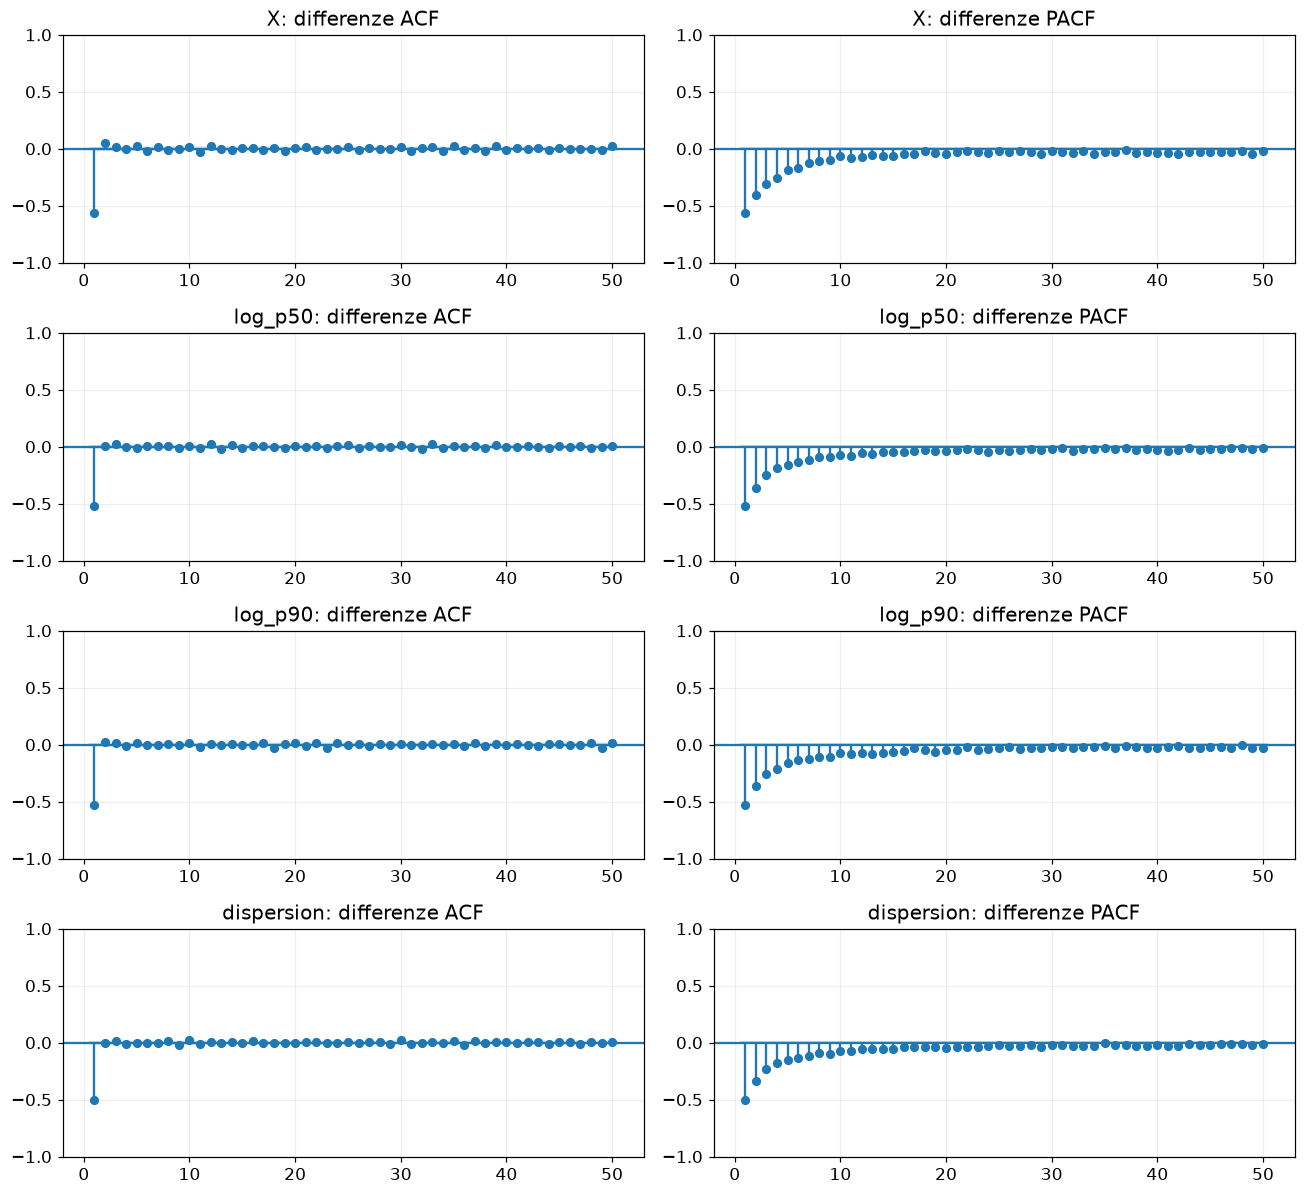

In [11]:
fig, axes = plt.subplots(len(variables), 2, figsize=(12, 11))
for row, (name, column) in enumerate(variables.items()):
    differences = sample[column].iloc[:TRAIN_END].diff().dropna()
    plot_acf(
        differences, lags=50, fft=True, zero=False, ax=axes[row, 0], title=f"{name}: differenze ACF"
    )
    plot_pacf(
        differences,
        lags=50,
        method="ywm",
        zero=False,
        ax=axes[row, 1],
        title=f"{name}: differenze PACF",
    )
fig.tight_layout()
plt.show()
plt.close(fig)

## 11. ACF e PACF dei residui

Verifichiamo quanta memoria rimane negli errori delle previsioni testing.
Una struttura residua indica che la sola media autoregressiva non ha assorbito tutta la dinamica.

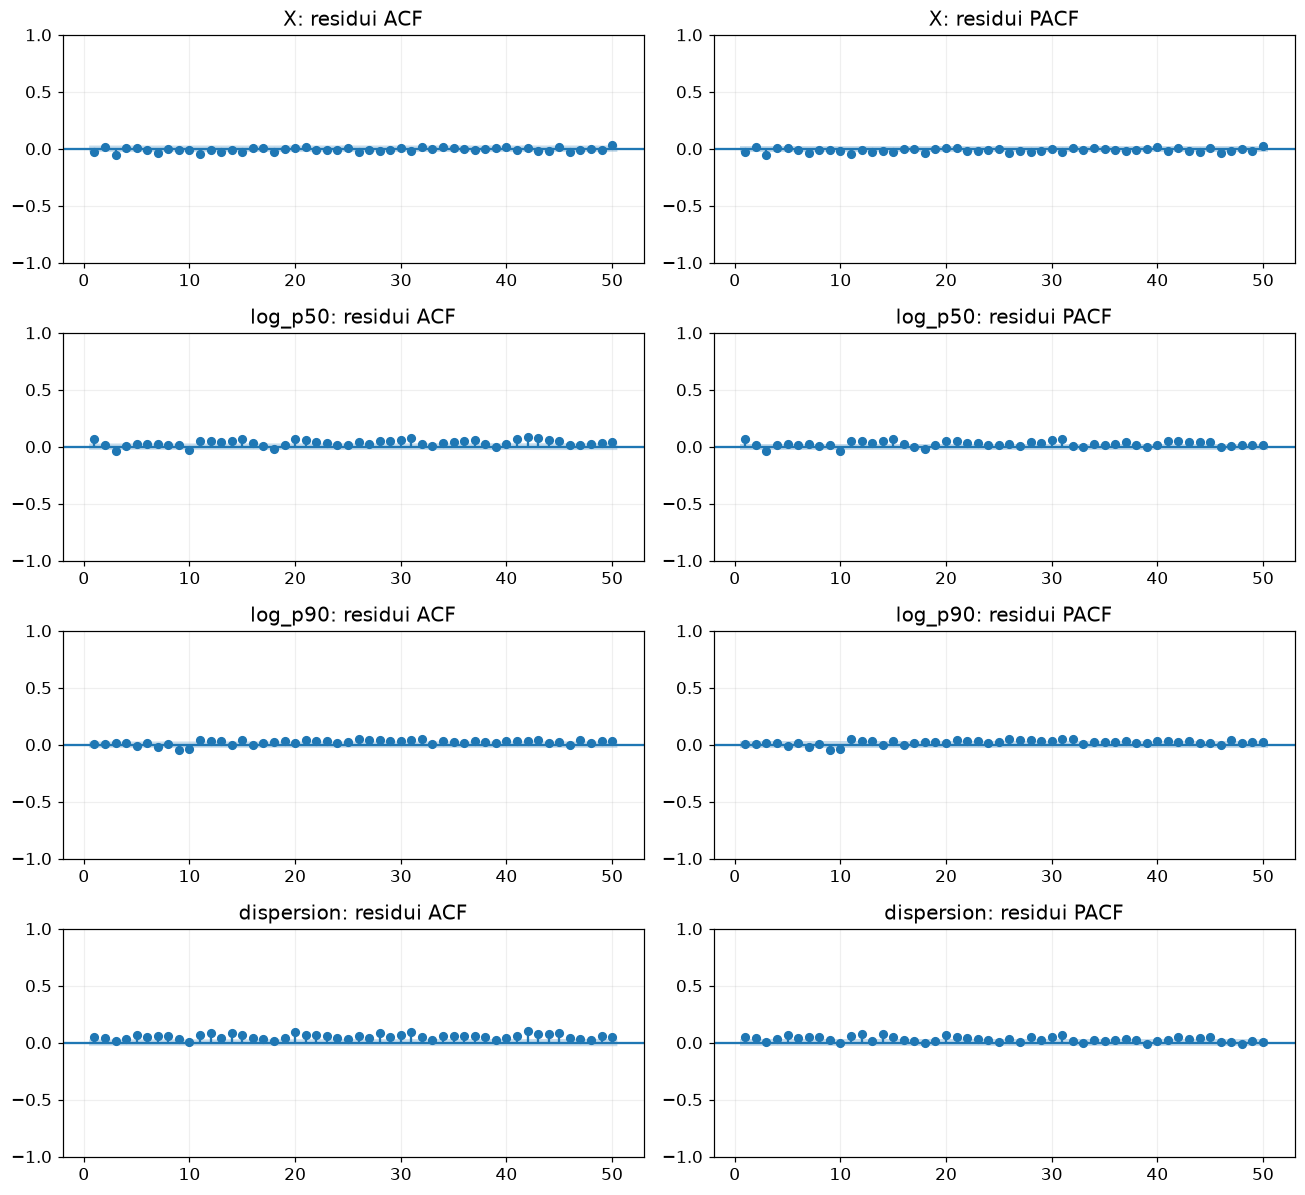

In [12]:
test_residuals = residuals.query("role == 'testing'")
fig, axes = plt.subplots(len(variables), 2, figsize=(12, 11))
for row, name in enumerate(variables):
    errors = test_residuals[f"residual_{name}"]
    plot_acf(errors, lags=50, fft=True, zero=False, ax=axes[row, 0], title=f"{name}: residui ACF")
    plot_pacf(
        errors, lags=50, method="ywm", zero=False, ax=axes[row, 1], title=f"{name}: residui PACF"
    )
fig.tight_layout()
plt.show()
plt.close(fig)

## 12. Ljung–Box ai lag 5, 10, 20 e 50

Verifichiamo congiuntamente le autocorrelazioni di livelli, differenze e residui nel testing.
Usiamo model_df=0: i coefficienti delle previsioni non sono stimati sui target del testing; i p-value restano diagnostici.

In [13]:
lb_tables = []
for name, column in variables.items():
    for label, values in [
        ("level", sample[column].iloc[VALID_END:]),
        ("difference", sample[column].diff().iloc[VALID_END:]),
        ("residual", test_residuals[f"residual_{name}"]),
    ]:
        table = acorr_ljungbox(values, lags=[5, 10, 20, 50], model_df=0, return_df=True)
        table = table.rename_axis("lag").reset_index().assign(variable=name, series=label)
        lb_tables.append(table)
ljung_box = pd.concat(lb_tables, ignore_index=True)
display(ljung_box.round(6))
ljung_box.to_csv(output_directory / "ljung_box.csv", index=False)

,lag,lb_stat,lb_pvalue,variable,series
0,5,158.139777,0.0,X,level
1,10,163.289885,0.0,X,level
2,20,189.292894,0.0,X,level
3,50,238.762006,0.0,X,level
4,5,1824.672195,0.0,X,difference
...,...,...,...,...,...
43,50,1357.191895,0.0,dispersion,difference
44,5,46.324095,0.0,dispersion,residual
45,10,95.830002,0.0,dispersion,residual
46,20,287.445816,0.0,dispersion,residual


## 13. Implicazioni per lo stato osservabile

Separiamo significatività residua ed effetto predittivo misurato sul testing.
Un vantaggio dei lag più vecchi motiva uno stato più ricco; nessun confronto dimostra da solo sufficienza Markoviana.

In [14]:
implications = []
for name, lag in selected_lags.items():
    scores = forecast_scores.query("variable == @name and role == 'testing'").set_index("lag")[
        "MSE"
    ]
    pvalue = ljung_box.query("variable == @name and series == 'residual' and lag == 50")[
        "lb_pvalue"
    ].iloc[0]
    implications.append(
        {
            "variable": name,
            "selected_lag": lag,
            "testing_MSE_improvement_vs_AR1_pct": 100 * (1 - scores.loc[lag] / scores.loc[1]),
            "testing_residual_LB50_p": pvalue,
        }
    )
implications = pd.DataFrame(implications)
display(implications)
implications.to_csv(output_directory / "state_implications.csv", index=False)

,variable,selected_lag,testing_MSE_improvement_vs_AR1_pct,testing_residual_LB50_p
0,X,10,1.135949,2.926050e-04
1,log_p50,10,22.536385,8.696231e-65
2,log_p90,10,12.101785,4.564933e-20
3,dispersion,10,17.847486,1.872925e-139
